In [ ]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import statsmodels as sm

In [3]:
df = pd.read_stata("dataset_merged.dta")

In [ ]:
# Transform advertisement types into binary columns
dummies = pd.get_dummies(df["ad_condition"], drop_first=True, dtype=int)
# Add those dummies to the dataframe and define as df2
df2 = pd.concat([df, dummies], axis=1)
# Rename binary columns for better readability
df2 = df2.rename(columns={
    1: "lostgirls_genre",
    2: "lostgirls_plain",
    3: "lostgirls_price",
    4: "stateline_genre",
    5: "stateline_plain",
    6: "stateline_price",
    "age_years": "age" 
})
# Group price ads across different genres
df2["price_ad"] = df2["lostgirls_price"] + df2["stateline_price"]
# Define the interaction term
df2["price_age"] = df2["price_ad"] * df2["age"]
# Group genre ads across different ad types; end result is stateline vs. lostgirls
df2["book_ad"] = df2["stateline_plain"] + df2["stateline_price"]
# Define a new column that takes lostgirls purchase information
df2["purchase"] = df2["purchased_203"]
# Insert the stateline purchase information into "purchase"
df2.loc[df2["book_ad"] == 1, "purchase"] = df2["purchased_303"]
# Define a new column that takes lostgirls search information
df2["search"] = df2["clicked_203"]
# Insert the stateline search information into "search"
df2.loc[df2["book_ad"] == 1, "search"] = df2["clicked_303"]
# Take observations that contains one of 2, 3, 5, 6 in the "ad_condition" column, and define as df3
df3 = df2[df2["ad_condition"].isin([2, 3, 5, 6])].copy()
# Define a list of relevant variables.
columns = [
    "purchase", "price_ad", "age", "book_ad", "price_age",
    "income1", "income2", "income3", "income4", "income5",
    "female", "black", "hispanic", "asian",
    "bachelor", "master", "some_college",
    "married", "divorced",
    "ebooks", "printbooks",
    "romance_rank", "mystery_rank",
    "fantasy_rank", "scifi_rank"
]

# Keep only relevant columns and remove missing observations
df4 = df3[columns].dropna().copy()

# Define a list of categorical variables
categorical = [
    "ebooks", "printbooks",
    "romance_rank", "mystery_rank",
    "fantasy_rank", "scifi_rank"
]

# Convert categorical variables into dummies
df4 = pd.get_dummies(
    df4,
    columns=categorical,
    drop_first=True,
    dtype=int
)

Baseline Model from the paper

In [ ]:

b_model_lg = smf.ols(
    "purchased_203 ~ lostgirls_genre + lostgirls_plain + lostgirls_price",
    data=df2[df2["ad_condition"].isin([0, 1, 2, 3])]
).fit(cov_type="HC1", use_t=True)


b_model_st = smf.ols(
    "purchased_303 ~ stateline_genre + stateline_plain + stateline_price",
    data=df2[df2["ad_condition"].isin([0, 4, 5, 6])]
).fit(cov_type="HC1", use_t=True)

print(b_model_lg.summary())
print(b_model_st.summary())

                            OLS Regression Results                            
Dep. Variable:          purchased_203   R-squared:                       0.004
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     10.36
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           8.43e-07
Time:                        13:19:22   Log-Likelihood:                -139.59
No. Observations:                5929   AIC:                             287.2
Df Residuals:                    5925   BIC:                             313.9
Df Model:                           3                                         
Covariance Type:                  HC1                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.0281      0.008     

In [48]:
# Lost Girls: Price versus Plain
lg_test = b_model_lg.t_test(
    "lostgirls_price - lostgirls_plain = 0"
)

# Stateline: Price versus Plain
st_test = b_model_st.t_test(
    "stateline_price - stateline_plain = 0"
)

print("Lost Girls:")
print(lg_test)

print("\nStateline:")
print(st_test)


Lost Girls:
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0193      0.009      2.219      0.027       0.002       0.036

Stateline:
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.0111      0.009      1.247      0.213      -0.006       0.028


My baseline model

In [11]:
my_b_model = smf.ols(
    "purchase ~ price_ad",
    data=df3
).fit(cov_type="HC1")

print(my_b_model.summary())

                            OLS Regression Results                            
Dep. Variable:               purchase   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     4.939
Date:                Wed, 28 Oct 2026   Prob (F-statistic):             0.0263
Time:                        15:02:10   Log-Likelihood:                -697.74
No. Observations:                6939   AIC:                             1399.
Df Residuals:                    6937   BIC:                             1413.
Df Model:                           1                                         
Covariance Type:                  HC1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0705      0.004     16.233      0.0

In [ ]:
full_model = smf.ols(
    """purchase ~ price_age + book_ad
    + C(ebooks) + C(printbooks)
    + C(romance_rank) + C(mystery_rank)
    + C(fantasy_rank) + C(scifi_rank)
    + income1 + income2 + income3 + income4 + income5
    + female + black + hispanic + asian
    + bachelor + master + some_college
    + married + divorced""",
    data=df4
).fit(cov_type="HC1")

print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:               purchase   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.021
Method:                 Least Squares   F-statistic:                     4.019
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           7.30e-17
Time:                        22:52:36   Log-Likelihood:                -605.87
No. Observations:                6939   AIC:                             1298.
Df Residuals:                    6896   BIC:                             1592.
Df Model:                          42                                         
Covariance Type:                  HC1                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0

Histogram

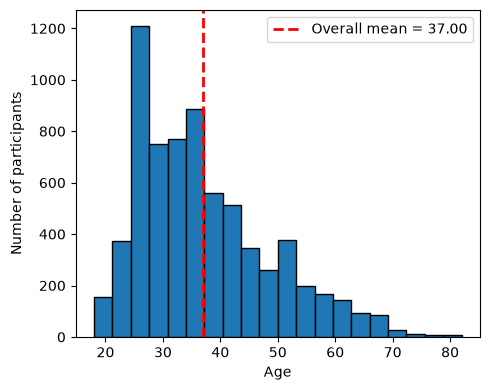

In [ ]:
plt.figure(figsize=(5,4))
plt.hist(df3["age"], bins=20, edgecolor="black")
plt.axvline(df3["age"].mean(), color = "red", linestyle="--", linewidth=2, label=f"Overall mean = {df3["age"].mean():.2f}")
plt.xlabel("Age")
plt.ylabel("Number of participants")
plt.legend()
plt.tight_layout()
plt.savefig("age_distribution.pdf", bbox_inches="tight")
plt.savefig("age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Histogram for each group

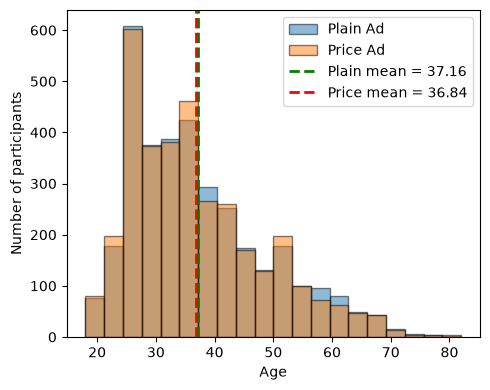

In [ ]:
# Define dfs that take the age for each ad group
plain_age = df4.loc[df4["price_ad"] == 0, "age"]
price_age = df4.loc[df4["price_ad"] == 1, "age"]

plt.figure(figsize=(5, 4))
# Plot a histogram
plt.hist(plain_age, bins=20, alpha=0.5, edgecolor="black", label="Plain Ad")
plt.hist(price_age, bins=20, alpha=0.5, edgecolor="black", label="Price Ad")

plt.axvline(plain_age.mean(), color = "green", linestyle="--", linewidth=2, label=f"Plain mean = {plain_age.mean():.2f}")
plt.axvline(price_age.mean(), color = "red", linestyle="--", linewidth=2, label=f"Price mean = {price_age.mean():.2f}")

plt.xlabel("Age")
plt.ylabel("Number of participants")
plt.legend()
plt.tight_layout()
plt.savefig("age_distribution_both_groups.pdf", bbox_inches="tight")
plt.savefig("age_distribution_both_groups.png", dpi=300, bbox_inches="tight")
plt.show()

Line Graph

In [ ]:
# Define the boundary values for each bin
age_bins = [18, 25, 35, 45, 55, 100]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55+"]
# Divide continuous values into categories
df3["age_group"] = pd.cut(df4["age"], bins=age_bins, labels=age_labels, right=False)

In [ ]:
# Group observations by "age_group" and "price_ad" and take the mean "purchase" value within the group
age_purchase = (
    df4.groupby(["age_group", "price_ad"])["purchase"]
       .mean()
       .reset_index()
)
# Take the mean values for each advertisement groups
plain = age_purchase[age_purchase["price_ad"] == 0]
price = age_purchase[age_purchase["price_ad"] == 1]

/var/folders/5y/v4jwjcp91p52g8rk8nfzycc80000gn/T/ipykernel_46001/3362129548.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df3.groupby(["age_group", "price_ad"])["purchase"]


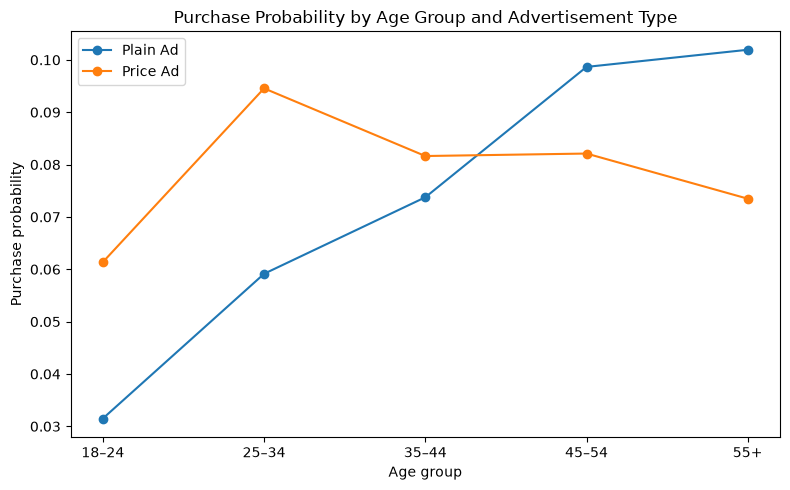

In [26]:
plt.figure(figsize=(8,5))
plt.plot(plain["age_group"], plain["purchase"], marker="o", label="Plain Ad")
plt.plot(price["age_group"], price["purchase"], marker="o", label="Price Ad")
plt.xlabel("Age group")
plt.ylabel("Purchase probability")
plt.title("Purchase Probability by Age Group and Advertisement Type")
plt.legend()
plt.tight_layout()
plt.savefig("purchase_probability.pdf", bbox_inches="tight")
plt.savefig("purchase_probability.png", dpi=300, bbox_inches="tight")
plt.show()

Summary Statistics

In [ ]:
# Define a column that takes the preference rank for the advertised book.
df4["genre_rank"] = np.where(
    df4["book_ad"] == 1,
    df4["mystery_rank"],
    df4["romance_rank"]
)

# Variables to summarize
cols = [
    "purchase", "search", "age",
    "female", "black", "hispanic", "asian",
    "income1", "income2", "income3",
    "income4", "income5", "income6",
    "bachelor", "master", "some_college",
    "married", "divorced",
    "printbooks", "ebooks", "genre_rank"
]

# Group the variables by "price_ad" and take the mean, transpose
summary = df4.groupby("price_ad")[cols].mean().T
# Name the columns as follows,
summary.columns = ["Plain ad", "Price ad"]

# Take the mean between columns
summary["Overall"] = df4[cols].mean()

# Convert purchase and search rates to percentages
summary.loc[["purchase", "search"]] *= 100

# Display
display(summary.round(2))


,Plain ad,Price ad,Overall
purchase,7.05,8.48,7.77
search,12.18,13.96,13.07
age,37.16,36.84,37.00
female,0.58,0.59,0.58
black,0.10,0.10,0.10
hispanic,0.05,0.06,0.05
asian,0.04,0.04,0.04
income1,0.09,0.09,0.09
income2,0.27,0.27,0.27
income3,0.30,0.28,0.29


Balance Table

In [ ]:
# Define a column that takes the preference rank for the advertised book.
df4["genre_rank"] = np.where(
    df4["book_ad"] == 1,
    df4["mystery_rank"],
    df4["romance_rank"]
)

# Covariates
cols = [
    "age", "female", "black", "hispanic", "asian",
    "income1", "income2", "income3", "income4", "income5", "income6",
    "bachelor", "master", "some_college",
    "married", "divorced",
    "printbooks", "ebooks", "genre_rank"
]

data = df4[["price_ad", "book_ad"] + cols].dropna()

# Group the variables by "price_ad" and take the mean, transpose
balance = data.groupby("price_ad")[cols].mean().T
# Name the columns as follows,
balance.columns = ["Plain ad", "Price ad"]

# Individual balance tests (controlling for advertised book)
X = sm.add_constant(data[["price_ad", "book_ad"]])

# Run a for loop that stores the coefficient and p-value for each covariate.
for col in cols:
    model = sm.OLS(data[col], X).fit(cov_type="HC1")
    balance.loc[col, "Difference"] = model.params["price_ad"]
    balance.loc[col, "p-value"] = model.pvalues["price_ad"]

# Joint balance test (omit income6 as reference)
joint_cols = []

# Construct a matrix that omits "income6" to avoid perfect colinearity
for c in cols:
    if c != "income6":
        joint_cols.append(c)

# Regress the treatment on other covariates.
X_joint = sm.add_constant(data[["book_ad"] + joint_cols])
joint = sm.OLS(data["price_ad"], X_joint).fit(cov_type="HC1")

# Create a list of hypotheses
tests = []
# add " = 0" for joint f-test
for c in joint_cols:
    tests.append(c + " = 0")

# Perform the joint F-test, store the p-value
joint_p = joint.f_test(tests).pvalue

# Add the p-value into the balance df.
balance.loc["Joint test (p-value)", "p-value"] = float(joint_p)

display(balance.round(4))


Joint p-value: 0.4548088489124826


,Plain ad,Price ad,Difference,p-value
age,37.1612,36.8410,-0.3217,0.2422
female,0.5802,0.5863,0.0061,0.6083
black,0.0985,0.0995,0.0010,0.8838
hispanic,0.0513,0.0580,0.0067,0.2162
asian,0.0397,0.0366,-0.0031,0.5012
income1,0.0855,0.0926,0.0071,0.3006
income2,0.2661,0.2706,0.0046,0.6669
income3,0.3018,0.2827,-0.0190,0.0818
income4,0.1713,0.1875,0.0162,0.0782
income5,0.1146,0.1102,-0.0044,0.5618


Attrition test

In [ ]:
# Original sample before dropping missing values
data = df3.copy()

# Identify observations excluded from df3
data["excluded"] = ~data.index.isin(df4.index)

# group by "price_ad" and take both "price_ad" and "excluded", sum each column and assign each name of the columns as "sum" and "count"
attrition = data.groupby("price_ad")["excluded"].agg(["sum", "count"])
# Rename each column as the following
attrition.columns = ["Excluded", "Total"]
# Calculate the number of included values
attrition["Included"] = attrition["Total"] - attrition["Excluded"]
# Calculate the exclusion rate
attrition["Exclusion Rate (%)"] = 100 * attrition["Excluded"] / attrition["Total"]
# Rename the indices
attrition.index = ["Plain ad", "Price ad"]

# Two-proportion Z-test
z, p = proportions_ztest(attrition["Excluded"], attrition["Total"])
attrition.index = ["Plain ad", "Price ad"]
attrition.loc["Z-test", "Z-statistic"] = z
attrition.loc["Z-test", "p-value"] = p

attrition

,Excluded,Total,Included,Exclusion Rate (%),Z-statistic,p-value
Plain ad,234.0,3707.0,3473.0,6.312382,NaN,NaN
Price ad,203.0,3669.0,3466.0,5.532843,NaN,NaN
Z-test,NaN,NaN,NaN,NaN,1.417896,0.156221
